# Sun's Blessing (Templar)

Sun's Blessing is a free self-buff. For 45 s it adds a bonus to all five attributes and half
that bonus to armor and weapon value. The cooldown is 55 s, so the buff is down for at least
10 s of every cycle (at most 82% uptime).

**Rebalanced.**
- The attribute bonus is `skill_knee_300(p_u, 6, 90)` (`suns_blessing_bonus`): +6 at skill 0,
  +90 at skill 300, then half that slope up to a hard limit of +120 at skill 515.
- Armor and weapon value get half the attribute bonus (`suns_blessing_gear_bonus`): +3 at
  skill 0, +45 at 300, +60 at most. Before, they got the full attribute bonus.
- The buff lasts 45 s instead of 180 s. Before, it outlasted the 55 s cooldown, so a recast
  refreshed it and the uptime was 100%.

The dotted "before" curves below show the previous version (180 s, full bonus on armor and
weapon).

| | |
|---|---|
| Class | Templar |
| Target | Self only |
| Cost | none |
| Cooldown | 55 s (separate `SK_SUNS_BLESSING` marker) |
| Landing roll | none |
| Duration | 45 s (was 180 s) |
| Effect | `attrib[0..5][1]` += `bonus`; `armor[1]`, `weapon[1]` += `⌊bonus / 2⌋` |
| Power | `unbuffed_skill_power`: the modified skill minus the part contributed by spell attribute bonuses |
| Source | `server/src/driver/skill/templar.rs::suns_blessing_bonus`, `suns_blessing_gear_bonus`, `skill_suns_blessing`; `driver/skill/common.rs::unbuffed_skill_power`, `skill_knee_300` |

---

# Formula

$$
\text{bonus} = \min\!\left(120,\ \begin{cases}
6 + \left\lfloor \tfrac{84\,p_u}{300} \right\rfloor & p_u \le 300 \\[4pt]
90 + \left\lfloor \tfrac{84(p_u - 300)}{600} \right\rfloor & p_u > 300
\end{cases}\right)
\qquad
\text{gear} = \left\lfloor \tfrac{\text{bonus}}{2} \right\rfloor
$$

`bonus` goes to every attribute; `gear` goes to armor and to weapon value.

$p_u$ is the *unbuffed* power: the modified skill with every active spell's attribute bonus
removed from the skill's three governing attributes. Without this, the buff's own +bonus to
attributes would feed back into the next recast.

$$
p_u = p - \left(\left\lfloor \tfrac{\sum a_5}{5} \right\rfloor - \left\lfloor \tfrac{\max(0,\ \sum (a_5 - a_\text{spell}))}{5} \right\rfloor\right)
$$

Each skill is derived from three attributes divided by 5, so +bonus to every attribute is worth
about $\tfrac{3}{5}\,\text{bonus}$ on **every** skill.

| Quantity | Attributes | Armor / weapon (now) | Armor / weapon (before) |
|---|---|---|---|
| Floor ($p_u = 0$) | +6 | +3 | +6 |
| Raise cap ($p_u$ 105 / 120) | +35 / +39 | +17 / +19 | +35 / +39 |
| Endgame ($p_u$ 275 / 300) | +83 / +90 | +41 / +45 | +83 / +90 |
| Beyond 300 ($p_u$ 350 / 450) | +97 / +111 | +48 / +55 | +97 / +111 |
| Hard limit | +120 from $p_u \ge 515$ | +60 | +120 |
| Duration / cooldown | 45 s / 55 s | | 180 s / 55 s |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BUFF_S = 45
OLD_BUFF_S = 180
COOLDOWN_S = 55

# Model

In [2]:
MAX_BONUS = 120


def sun_bonus(p_unbuffed):
    """`suns_blessing_bonus`: the attribute bonus."""
    return np.minimum(mm.knee_300(p_unbuffed, 6, 90), MAX_BONUS)


def gear_bonus(p_unbuffed):
    """`suns_blessing_gear_bonus`: the armor and weapon value bonus."""
    return mm.idiv(sun_bonus(p_unbuffed), 2)


# Before: armor and weapon value got the full attribute bonus.
old_gear_bonus = sun_bonus


def uptime(buff_s, cooldown_s=COOLDOWN_S):
    """Best-case fraction of time buffed when recast as soon as the cooldown allows."""
    return min(1.0, buff_s / cooldown_s)


def unbuffed_skill_power(skill5, attribs5, spell_bonus):
    """`unbuffed_skill_power` for one skill: attribs5 / spell_bonus are its three attributes."""
    buffed = sum(attribs5)
    base = sum(a - s for a, s in zip(attribs5, spell_bonus))
    return skill5 - (buffed // 5 - max(0, base) // 5)


def incoming_reduction(p, wv, base_armor=20, strength=80, gear=gear_bonus):
    """Fraction of one attacker's per-hit damage removed by the armor bonus."""
    before = mm.melee_hit_hp(wv, strength, base_armor)
    after = mm.melee_hit_hp(wv, strength, base_armor + np.asarray(gear(p)))
    return 1 - after / before


def outgoing_gain(p, wv, strength=80, armor=20, gear=gear_bonus):
    """Per-hit damage multiplier from +gear weapon value and +bonus STR."""
    g = np.atleast_1d(gear(p))
    b = np.atleast_1d(sun_bonus(p))
    after = np.array([mm.melee_hit_hp(wv + x, strength + y, armor) for x, y in zip(g, b)])
    out = after / mm.melee_hit_hp(wv, strength, armor)
    return mm._scalar(out if np.ndim(p) else out[0])

# Validation

- `suns_blessing_grants_bonuses_and_a_separate_cooldown`: power 40 gives +17 to every attribute
  and +8 to armor and weapon. The buff lasts `TICKS*45`, the cooldown `TICKS*55`, and a recast
  during the cooldown keeps the same item.
- `suns_blessing_bonus_is_capped`: power 1000 gives +120 attributes and +60 armor and weapon.
- `templar_bonuses_reach_their_design_value_at_skill_300`: `suns_blessing_bonus` 0 → 6,
  300 → 90, 450 → 111, 2000 → 120; `suns_blessing_gear_bonus` 0 → 3, 300 → 45, 2000 → 60.
- `unbuffed_skill_power_strips_spell_attribute_bonuses`: skill 69 with attributes at 65 stays 69.
  With +15 from a spell on each attribute it becomes 60.

In [3]:
assert sun_bonus(40) == 17 and gear_bonus(40) == 8
assert sun_bonus(1000) == 120 and gear_bonus(1000) == 60
assert [int(sun_bonus(p)) for p in (0, 300, 450, 2000)] == [6, 90, 111, 120]
assert [int(gear_bonus(p)) for p in (0, 300, 2000)] == [3, 45, 60]
assert [int(sun_bonus(p)) for p in (105, 120, 275, 350, 514, 515)] == [35, 39, 83, 97, 119, 120]
assert [int(gear_bonus(p)) for p in (105, 120, 275, 350, 450)] == [17, 19, 41, 48, 55]
assert mm.TICKS * BUFF_S == 1620 and mm.TICKS * COOLDOWN_S == 1980 and BUFF_S < COOLDOWN_S
assert unbuffed_skill_power(69, (65, 65, 65), (0, 0, 0)) == 69
assert unbuffed_skill_power(69, (65, 65, 65), (15, 15, 15)) == 60
print("Sun's Blessing model OK")

Sun's Blessing model OK


# Plots

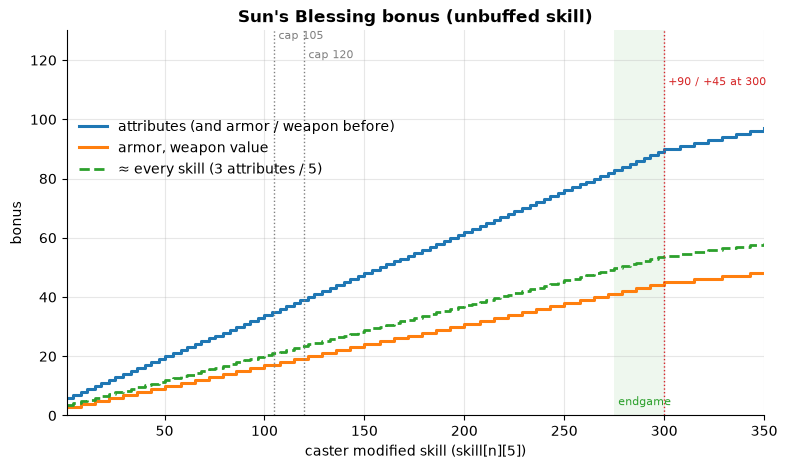

In [4]:
fig, ax = plt.subplots()
ax.step(P, sun_bonus(P), where="post", lw=2.2, label="attributes (and armor / weapon before)")
ax.step(P, gear_bonus(P), where="post", lw=2.2, label="armor, weapon value")
ax.step(P, sun_bonus(P) * 3 / 5, where="post", ls="--", label="≈ every skill (3 attributes / 5)")
mm.skill_axis(ax, "bonus", "Sun's Blessing bonus (unbuffed skill)")
mm.mark_caps(ax, extra=[(mm.SKILL_KNEE, "+90 / +45 at 300")])
ax.set_ylim(0, 130)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.8))

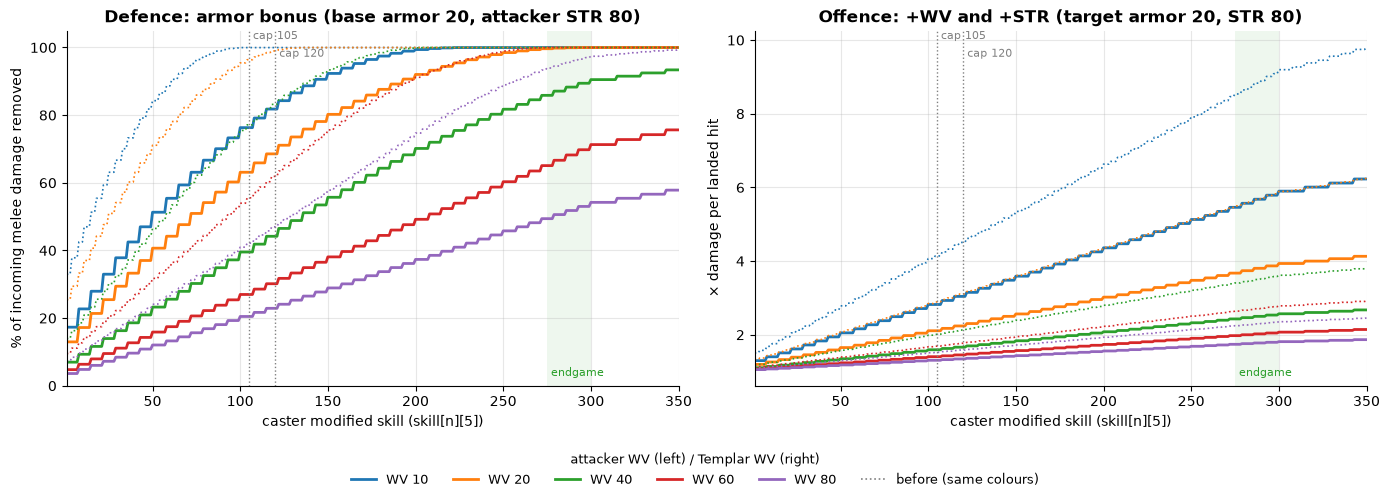

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for wv in mm.WV_SWEEP:
    line, = ax.plot(P, 100 * incoming_reduction(P, wv), label=f"WV {wv}")
    ax.plot(P, 100 * incoming_reduction(P, wv, gear=old_gear_bonus), color=line.get_color(), lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "% of incoming melee damage removed", "Defence: armor bonus (base armor 20, attacker STR 80)")
ax.set_ylim(0, 105)
mm.mark_caps(ax)

ax = axes[1]
for wv in mm.WV_SWEEP:
    line, = ax.plot(P, outgoing_gain(P, wv))
    ax.plot(P, outgoing_gain(P, wv, gear=old_gear_bonus), color=line.get_color(), lw=1.2, ls=":")
mm.skill_axis(ax, "× damage per landed hit", "Offence: +WV and +STR (target armor 20, STR 80)")
mm.mark_caps(ax)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=6, fontsize=9,
           title="attacker WV (left) / Templar WV (right)", title_fontsize=9)
plt.tight_layout(rect=(0, 0.1, 1, 1))

# Observations

- The buff no longer stays up. It lasts 45 s against a 55 s cooldown, so even a perfectly timed
  recast leaves a 10 s gap every cycle (at most 82% uptime, was 100%). The recast is blocked
  while the cooldown runs, so the old refresh-forever loop is gone.
- Attributes are unchanged: +35 at skill 105, +90 at 300, +120 at 515. That is still about +21
  to every skill at 105 (Weapon Skill, Resist, Immunity included) and +54 at 300, so the
  to-hit swing (60% → 90% in an even fight at 105) is the same while the buff is up.
- Armor and weapon value get half the attribute bonus: +17 at skill 105, +45 at 300, +60 at
  most (was +35 / +90 / +120).
- Defence against base armor 20 at skill 105: the armor bonus removes 40% of a WV-40 STR-80
  attacker's damage per hit (was 77%) and 27% of a WV-60 attacker's (was 56%). At skill 300 it
  removes 91% (WV 40), 71% (WV 60) and 54% (WV 80). Only WV-20 attackers are fully nullified,
  from skill 300. Before, WV-20/40/60/80 were nullified from 140/211/283/408.
- Offence: +WV and +STR multiply a WV-40 Templar's damage per landed hit against armor 20 by
  ×1.59 at skill 105 (10.75 → 17.1 HP, was ×2.01) and ×2.57 at 300 (→ 27.6 HP, was ×3.62).
- The buff's own attribute bonus is stripped before the bonus is computed, so recasting does not
  compound. Other attribute buffs (Bless, Sun's Blessing itself) do not raise it either.
- Still open: it costs nothing, and the attribute half (every skill +3/5 of the bonus) is now the
  dominant part of the buff. If it is still too strong, the next levers are a mana cost or a
  lower attribute target such as `skill_knee_300(p_u, 6, 60)`.